# Component 01: Multi-Modal Sensor EDA & Embedded DSP Validation
### AI-Powered Predictive Maintenance for Industrial Air Compressors (J26-SE-326)
**Lead Researcher:** Weerakoon W.M.M.B (`IT23155152`)  
**Hardware Architecture:** Rev 3.0 Left-Edge Master Signal Bus (ESP32-S3 DevKitC-1 N16R8)  
**Deliverable:** Progress Presentation 1 (PP1) - Day 2 Milestone  

---

## 1. Research Overview & Problem Statement
In industrial reciprocating air compressors, raw time-series sensor telemetry exhibits high-frequency noise, mechanical baseline gravity offsets ($9.81\,\text{m/s}^2$), and multi-rate sampling disparities (mechanical vibration @ 25 Hz vs. thermodynamic temperature @ 1 Hz).

Before feeding data into edge anomaly detection models (INT8 1D-CNN autoencoders / statistical Mahalanobis distance) or downstream Remaining Useful Life (RUL) models (Component 02), this notebook accomplishes:
1. **Exploratory Data Analysis (EDA):** Verifying physical sensor dynamics across all 5 modalities (Pressure, Motor Current, Acoustic Noise, 3-Axis Vibration, Temperature).
2. **Embedded-Equivalent DSP Extraction:** Formulating sliding-window statistical features (RMS, ISO 10816 vibration severity, Kurtosis, dynamic AC Crest Factor, and $\Delta P/\Delta t$).
3. **Contract Conformance:** Verifying complete alignment with `c01_to_c02_telemetry_contract.json`.
4. **Feature Dataset Export:** Generating `c01_edge_sensor_fusion/data/processed/sliding_window_features.csv`.

## 2. Environment Setup & Dependency Imports

In [1]:
import os
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Ensure project src directory is accessible
SRC_DIR = os.path.abspath(os.path.join(os.getcwd(), '..', 'src'))
if SRC_DIR not in sys.path:
    sys.path.insert(0, SRC_DIR)

from dsp_pipeline import MultiModalDSPPipeline

# Configure publication styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120
print("[OK] Environment initialized successfully.")

[OK] Environment initialized successfully.


## 3. Telemetry Ingestion & Exploratory Data Analysis (EDA)
We load `data/raw/baseline_compressor_runs.csv` captured from the ESP32-S3 testbed acquisition system.

In [2]:
RAW_DATA_PATH = os.path.join('..', 'data', 'raw', 'baseline_compressor_runs.csv')
df_raw = pd.read_csv(RAW_DATA_PATH)

print(f"Dataset Shape: {df_raw.shape[0]} samples x {df_raw.shape[1]} channels")
print(f"Sampling Frequency: 25.0 Hz (40 ms packet interval)")
print(f"Total Run Duration: {(df_raw['timestamp_ms'].iloc[-1] - df_raw['timestamp_ms'].iloc[0]) / 1000.0:.2f} seconds")
print("\n--- Sample Telemetry Head ---")
display(df_raw.head())

Dataset Shape: 396 samples x 13 channels
Sampling Frequency: 25.0 Hz (40 ms packet interval)
Total Run Duration: 15.80 seconds

--- Sample Telemetry Head ---


,timestamp_iso,timestamp_ms,temp_c,press_psi,press_v,curr_a,curr_v,sound_mv,vib_x,vib_y,vib_z,anomaly,relay
0,2026-10-11T18:11:02.571193+00:00,40,28.84,32.21,1.503,5.039,1.983,103.0,9.77,-0.16,-0.16,0,0
1,2026-10-11T18:11:02.611587+00:00,80,28.33,32.16,1.501,5.085,1.986,97.7,9.49,0.24,-0.14,0,0
2,2026-10-11T18:11:02.651886+00:00,120,28.81,31.76,1.486,4.784,1.966,93.8,9.56,0.26,-0.15,0,0
3,2026-10-11T18:11:02.692105+00:00,160,28.46,32.40,1.510,4.758,1.964,100.7,10.10,-0.13,-0.01,0,0
4,2026-10-11T18:11:02.732762+00:00,200,28.36,32.05,1.497,5.060,1.984,94.2,9.62,-0.02,0.05,0,0


In [3]:
print("--- Summary Statistics of Raw Multi-Modal Channels ---")
channels = ['temp_c', 'press_psi', 'curr_a', 'sound_mv', 'vib_x', 'vib_y', 'vib_z']
display(df_raw[channels].describe().round(3))

anom_counts = df_raw['anomaly'].value_counts()
relay_counts = df_raw['relay'].value_counts()
print(f"Operational State Breakdown: Normal = {anom_counts.get(0, 0)}, Anomaly = {anom_counts.get(1, 0)}")
print(f"Fail-Safe Interlock Trips: Energized (Normal) = {relay_counts.get(0, 0)}, Tripped = {relay_counts.get(1, 0)}")

--- Summary Statistics of Raw Multi-Modal Channels ---


,temp_c,press_psi,curr_a,sound_mv,vib_x,vib_y,vib_z
count,396.000,396.000,396.000,396.000,396.000,396.000,396.000
mean,29.457,33.488,5.261,112.364,9.813,0.034,0.016
std,1.965,4.842,1.030,56.882,0.783,0.463,0.399
min,28.200,29.160,4.601,60.100,6.330,-1.800,-1.600
25%,28.428,31.708,4.769,77.975,9.570,-0.162,-0.180
50%,28.650,32.175,4.917,92.550,9.810,0.020,0.010
75%,28.862,32.520,5.073,106.650,10.032,0.200,0.182
max,35.390,48.980,8.693,301.900,13.520,2.360,1.840


Operational State Breakdown: Normal = 316, Anomaly = 80
Fail-Safe Interlock Trips: Energized (Normal) = 356, Tripped = 40


## 4. Multi-Modal Time-Series Inspection
Visualizing the raw signals across the three distinct operational regimes:
1. **Normal Baseline Operation** (Packets 0–119, 160–239, 280–395)
2. **Impulsive Mechanical Knock / Bearing Fault** (Packets 120–159)
3. **Pneumatic Overpressure & Fail-Safe Cut-Off** (Packets 240–279, exceeding 45 PSI limit)

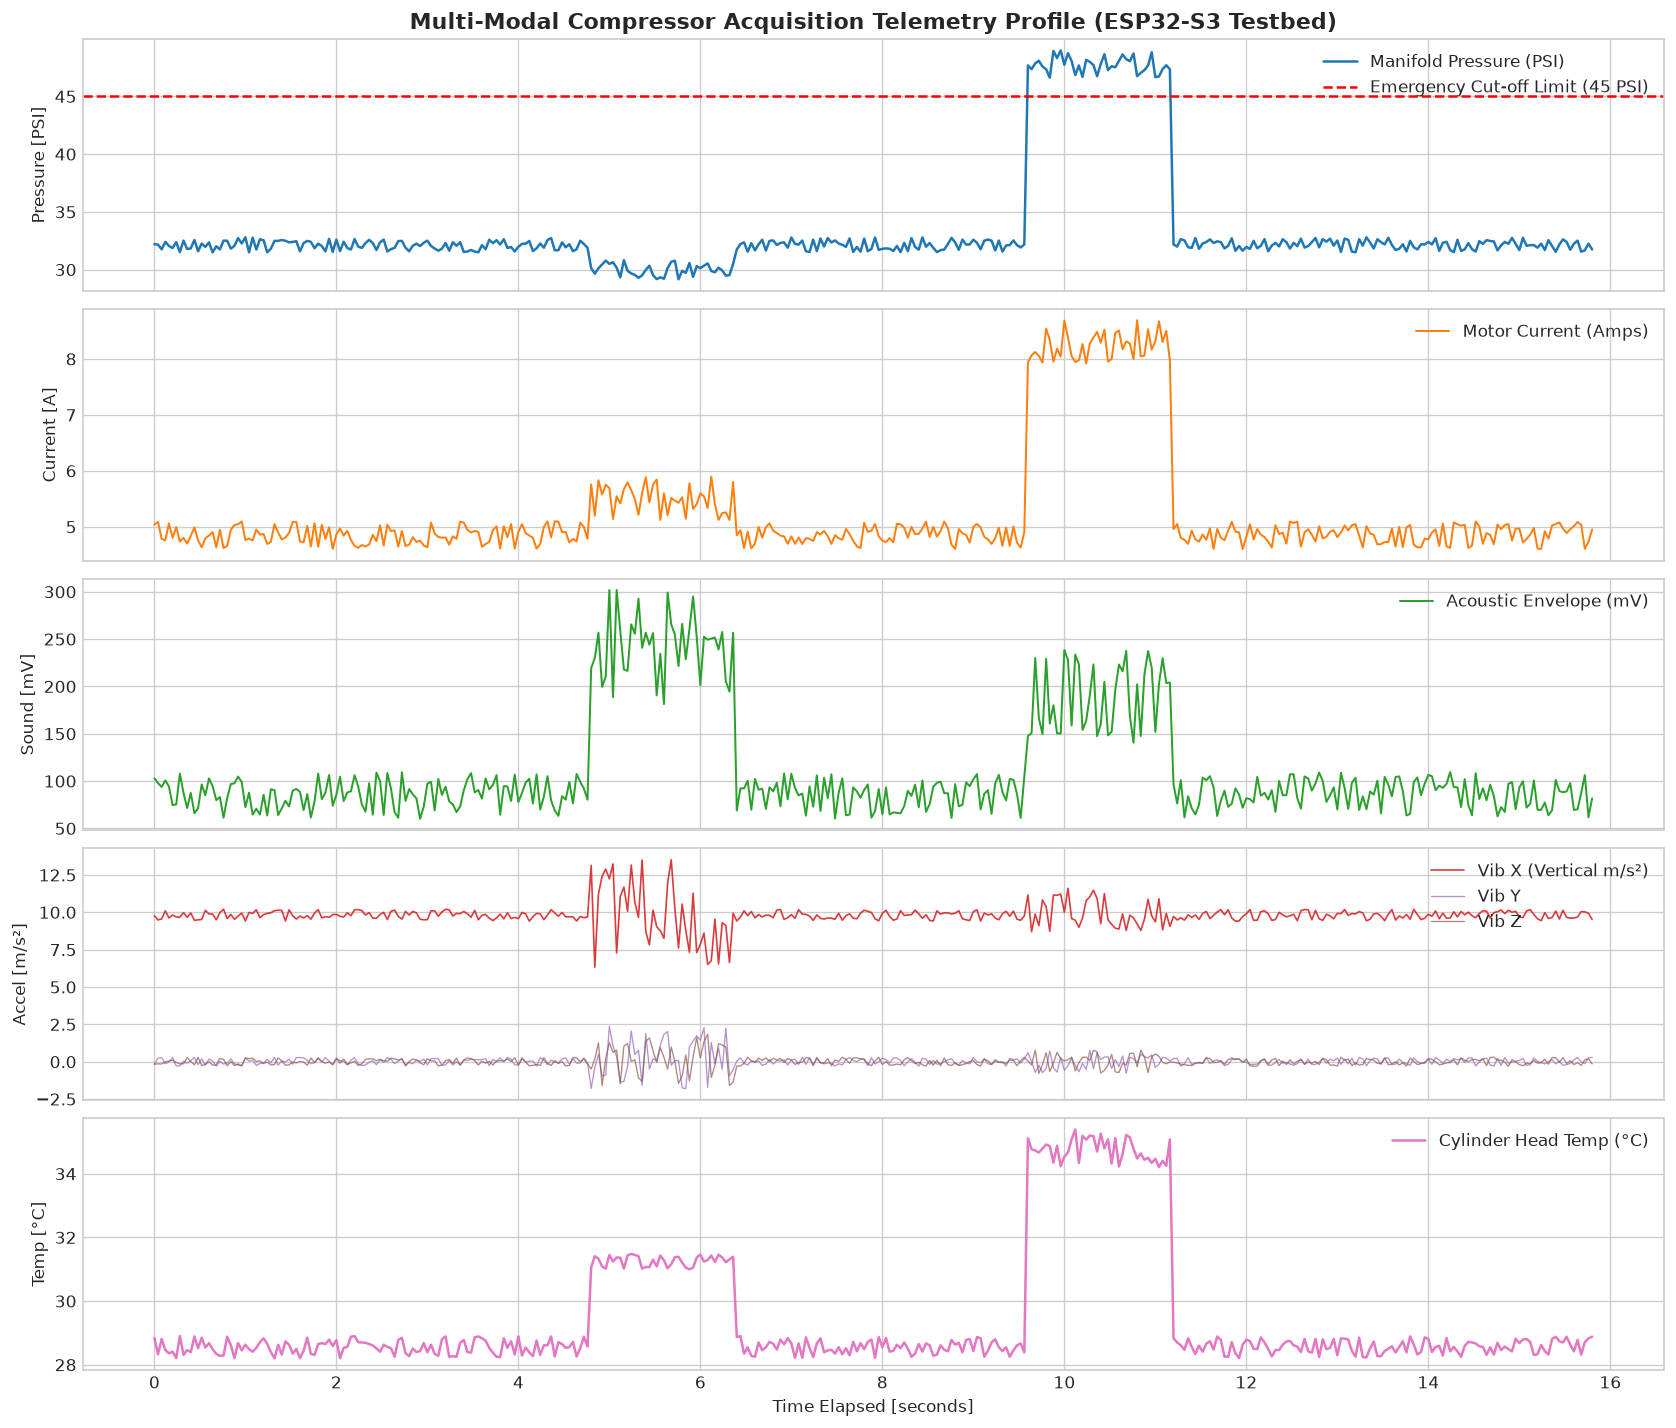

In [4]:
fig, axes = plt.subplots(5, 1, figsize=(14, 12), sharex=True)
time_sec = (df_raw['timestamp_ms'] - df_raw['timestamp_ms'].iloc[0]) / 1000.0

# 1. Pressure Transducer
axes[0].plot(time_sec, df_raw['press_psi'], color='#1f77b4', lw=1.5, label='Manifold Pressure (PSI)')
axes[0].axhline(45.0, color='red', linestyle='--', label='Emergency Cut-off Limit (45 PSI)')
axes[0].set_ylabel('Pressure [PSI]')
axes[0].set_title('Multi-Modal Compressor Acquisition Telemetry Profile (ESP32-S3 Testbed)', fontsize=13, fontweight='bold')
axes[0].legend(loc='upper right')

# 2. Motor Current
axes[1].plot(time_sec, df_raw['curr_a'], color='#ff7f0e', lw=1.2, label='Motor Current (Amps)')
axes[1].set_ylabel('Current [A]')
axes[1].legend(loc='upper right')

# 3. Acoustic Microphone
axes[2].plot(time_sec, df_raw['sound_mv'], color='#2ca02c', lw=1.2, label='Acoustic Envelope (mV)')
axes[2].set_ylabel('Sound [mV]')
axes[2].legend(loc='upper right')

# 4. 3-Axis Accelerometer
axes[3].plot(time_sec, df_raw['vib_x'], color='#d62728', lw=1.0, alpha=0.9, label='Vib X (Vertical m/s²)')
axes[3].plot(time_sec, df_raw['vib_y'], color='#9467bd', lw=0.8, alpha=0.7, label='Vib Y')
axes[3].plot(time_sec, df_raw['vib_z'], color='#8c564b', lw=0.8, alpha=0.7, label='Vib Z')
axes[3].set_ylabel('Accel [m/s²]')
axes[3].legend(loc='upper right')

# 5. Cylinder Head Temperature
axes[4].plot(time_sec, df_raw['temp_c'], color='#e377c2', lw=1.5, label='Cylinder Head Temp (°C)')
axes[4].set_ylabel('Temp [°C]')
axes[4].set_xlabel('Time Elapsed [seconds]')
axes[4].legend(loc='upper right')

plt.tight_layout()
plt.show()

## 5. Sliding-Window DSP Algorithm & Feature Extraction
We now execute `MultiModalDSPPipeline` to calculate the on-device feature representations:
- **Vibration RMS & ISO Composite RMS:** $x_{\text{RMS}} = \sqrt{\frac{1}{N}\sum x_i^2}$
- **Pearson Kurtosis:** Quantifies impulsive shock transients:
  $$\text{Kurt}(x) = \frac{\frac{1}{N}\sum (x_i - \bar{x})^4}{\sigma^4}$$
- **Dynamic AC Crest Factor:** Peak dynamic excursion divided by dynamic standard deviation:
  $$C_{\text{AC}} = \frac{\max |x_i - \bar{x}|}{\sigma}$$
- **Dynamic Rate of Pressure Change:** $\frac{\Delta P}{\Delta t} = \frac{P_t - P_{t-W}}{\Delta t}$ (PSI/second)

In [5]:
pipeline = MultiModalDSPPipeline(vib_window=64, press_window=16, curr_window=32, sound_window=32)
df_features = pipeline.process_dataframe(df_raw)

print(f"Extracted Feature DataFrame: {df_features.shape[0]} rows x {df_features.shape[1]} columns")
display(df_features[['vibration_x_rms_ms2', 'vibration_composite_rms_ms2', 'vibration_kurtosis', 'vibration_crest_factor', 'delta_pressure_dt', 'motor_current_rms_a', 'acoustic_energy_mv']].head())

Extracted Feature DataFrame: 396 rows x 17 columns


,vibration_x_rms_ms2,vibration_composite_rms_ms2,vibration_kurtosis,vibration_crest_factor,delta_pressure_dt,motor_current_rms_a,acoustic_energy_mv
0,9.770,9.773,3.0,0.0,0.000,5.039,103.0
1,9.631,9.634,3.0,0.0,-1.250,5.062,100.4
2,9.607,9.611,3.0,0.0,-5.625,4.971,98.2
3,9.733,9.736,3.0,0.0,1.583,4.919,98.9
4,9.710,9.713,3.0,0.0,-1.000,4.947,97.9


## 6. DSP Feature Diagnostic Validation
Here we validate whether our DSP algorithms successfully isolate faults:
1. **Kurtosis & Crest Factor** should spike dramatically during bearing knocks while baseline remains mesokurtic ($\approx 3.0$).
2. **$\Delta P/\Delta t$** should elevate during overpressure pressurization and plunge during relief cutoff.

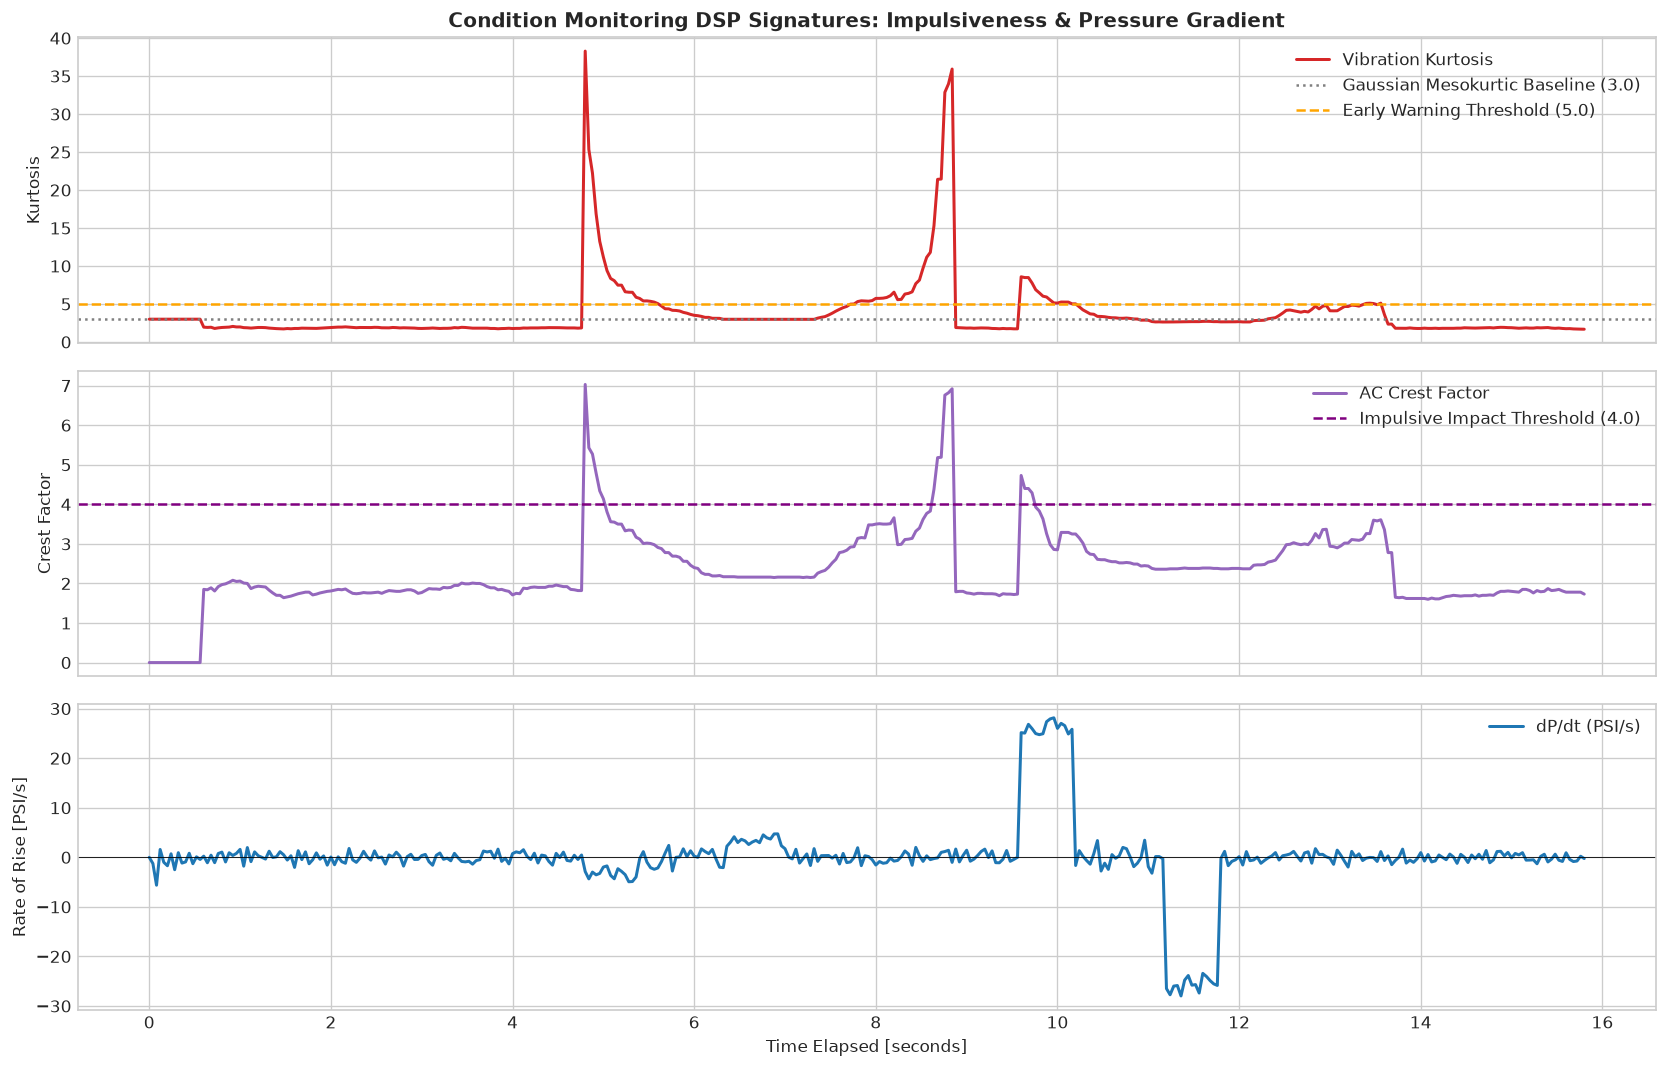

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)

# 1. Kurtosis vs Baseline
axes[0].plot(time_sec, df_features['vibration_kurtosis'], color='#d62728', lw=1.8, label='Vibration Kurtosis')
axes[0].axhline(3.0, color='gray', linestyle=':', label='Gaussian Mesokurtic Baseline (3.0)')
axes[0].axhline(5.0, color='orange', linestyle='--', label='Early Warning Threshold (5.0)')
axes[0].set_ylabel('Kurtosis')
axes[0].set_title('Condition Monitoring DSP Signatures: Impulsiveness & Pressure Gradient', fontsize=12, fontweight='bold')
axes[0].legend(loc='upper right')

# 2. Dynamic Crest Factor
axes[1].plot(time_sec, df_features['vibration_crest_factor'], color='#9467bd', lw=1.8, label='AC Crest Factor')
axes[1].axhline(4.0, color='purple', linestyle='--', label='Impulsive Impact Threshold (4.0)')
axes[1].set_ylabel('Crest Factor')
axes[1].legend(loc='upper right')

# 3. Delta P / Delta t
axes[2].plot(time_sec, df_features['delta_pressure_dt'], color='#1f77b4', lw=1.8, label='dP/dt (PSI/s)')
axes[2].axhline(0.0, color='black', linestyle='-', lw=0.5)
axes[2].set_ylabel('Rate of Rise [PSI/s]')
axes[2].set_xlabel('Time Elapsed [seconds]')
axes[2].legend(loc='upper right')

plt.tight_layout()
plt.show()

## 7. Inter-Component Contract Verification & Feature Export
We verify that the generated feature schema strictly conforms to the team's shared contract: `shared/interfaces/c01_to_c02_telemetry_contract.json`.

In [7]:
CONTRACT_PATH = os.path.abspath(os.path.join(os.getcwd(), '..', '..', 'shared', 'interfaces', 'c01_to_c02_telemetry_contract.json'))
is_valid, validation_msg = pipeline.validate_schema(df_features, CONTRACT_PATH)

print("=== Contract Conformance Report ===")
print(f"Target Contract: {os.path.basename(CONTRACT_PATH)}")
print(f"Status: {'[PASSED]' if is_valid else '[FAILED]'}")
print(f"Details: {validation_msg}")
assert is_valid, f"Contract verification failed: {validation_msg}"

=== Contract Conformance Report ===
Target Contract: c01_to_c02_telemetry_contract.json
Status: [PASSED]
Details: All required schema contract features verified successfully.


In [8]:
PROCESSED_DATA_PATH = os.path.join('..', 'data', 'processed', 'sliding_window_features.csv')
os.makedirs(os.path.dirname(PROCESSED_DATA_PATH), exist_ok=True)
df_features.to_csv(PROCESSED_DATA_PATH, index=False)

file_size_kb = os.path.getsize(PROCESSED_DATA_PATH) / 1024.0
print(f"[SUCCESS] Exported processed feature dataset to {PROCESSED_DATA_PATH}")
print(f"File Size: {file_size_kb:.2f} KB | Total Feature Rows: {len(df_features)}")

[SUCCESS] Exported processed feature dataset to ../data/processed/sliding_window_features.csv
File Size: 45.49 KB | Total Feature Rows: 396
